# E05 — Risco inicial do projeto em contexto municipal

**Versão 1.0 — 28/10/2026 — contribuição de Samuel Colaço.**

Dados exclusivamente públicos. Comparação de **Decision Tree Classifier**, **Random Forest Classifier**, baseline trivial e baseline operacional de referência (**Regressão Logística**).

O alvo atualizado é **`sem_repasse_90d`**: 1 se não houver desembolso positivo entre a assinatura e o dia 90, inclusive; 0 se houver. Não se prevê diretamente estouro de custo, margem ou fracasso definitivo. Uma linha representa um instrumento municipal da PB; características do município são contexto, não um alvo municipal agregado.

**Achado de viabilidade:** o treino desta versão possui uma única classe. O notebook não oculta essa restrição: árvores podem ser ajustadas, mas aprendem uma regra constante; a Logística não é estimável. O teste não autoriza fabricar exemplos ou trocar o horizonte.

## 1. Reprodução e proveniência

Execute os comandos de coleta e preparação descritos no README antes deste notebook. A execução abaixo é **offline**: confere o hash da base congelada e utiliza o mesmo código compartilhado da CLI. Instale `requirements-e05.txt` no ambiente Python x64 e execute da raiz do repositório.

As fontes são Transferegov Discricionárias, Transferências Especiais como histórico, IBGE e SICONFI DCA/RGF. As datas públicas de divulgação/envio são respeitadas; registros tardios e revisões atuais impedem afirmar que a reconstrução é uma fotografia histórica integral.

In [1]:
from pathlib import Path
import sys, json, os
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'config.e05.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'config.e05.json').exists(), 'Execute o notebook a partir do projeto'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.e05.__main__ import ler_base
from src.e05.dados import PREDITORES, NUMERICAS, CATEGORICAS
from src.e05.experimento import executar, criar_pipeline
from src.e05.relatorio import figuras
from unittest.mock import patch
# Nenhum download faz parte da execução do notebook.
_bloqueio_rede = patch('requests.Session.request', side_effect=RuntimeError('Notebook E05 executado offline'))
_bloqueio_rede.start()

PASTA = Path(os.environ.get('E05_OUTPUT_DIR', str(ROOT / 'output/e05')))
CONFIG = json.loads((ROOT / 'config.e05.json').read_text(encoding='utf-8'))
SEED = CONFIG['random_state']
base, manifesto = ler_base(PASTA)
assert manifesto['configuracao'] == CONFIG
print('SHA-256:', manifesto['sha256_dataset'])
print('Carga Transferegov:', manifesto['data_carga_transferegov'])
print('Ambiente:', manifesto['ambiente'])
print('Instrumentos:', len(base))

SHA-256: 20199701c46463aa8d800bceffca383411314a1193cb890e0115710a21d1085a
Carga Transferegov: 17/07/2026 06:30:47
Ambiente: {'python': '3.12.14', 'arquitetura': 'AMD64', 'pacotes': {'pandas': '2.3.3', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'pyarrow': '21.0.0'}}
Instrumentos: 867


## 2. Contrato, seguimento e partições

Pré-convênios não entram. Desembolso zero não caracteriza repasse; desembolso anterior à assinatura é inconsistência. Seguimento incompleto não recebe classe 1. A janela de 90 dias é técnica e não representa um prazo legal.

Desenvolvimento em 2022 → validação em 2023 → reajuste em 2022–2023 → teste em 2024. Para validar 2023, o rótulo precisa estar conhecido antes de 01/01/2023. Para o ajuste final, antes de 01/01/2024. Por isso assinaturas recentes podem ser excluídas do ajuste mesmo pertencendo ao ano de treino. Os mesmos IDs são usados por todos os métodos.

In [2]:
coortes = base.groupby('ano_coorte').agg(
    instrumentos=('nr_convenio', 'size'),
    classe_0=('sem_repasse_90d', lambda s: int((s == 0).sum())),
    classe_1=('sem_repasse_90d', lambda s: int((s == 1).sum())),
    excluidos_corte=('exclusao_temporal', 'sum'))
display(coortes)
suporte = []
for nome in ['treino_validacao', 'validacao', 'treino_final', 'teste']:
    q = base[base[nome]]
    suporte.append({'particao': nome, 'n': len(q), 'classe_0': int((q.sem_repasse_90d == 0).sum()),
                    'classe_1': int((q.sem_repasse_90d == 1).sum())})
display(pd.DataFrame(suporte))
assert not set(base.loc[base.treino_final, 'nr_convenio']) & set(base.loc[base.teste, 'nr_convenio'])
assert (base.loc[base.treino_final, 'fim_horizonte'] < pd.Timestamp('2024-01-01')).all()
display(base.motivo_exclusao.fillna('sem_problema_qualidade').value_counts().to_frame('n'))

,instrumentos,classe_0,classe_1,excluidos_corte
ano_coorte,,,,
2022,239,0,239,0
2023,386,0,386,309
2024,242,1,241,0


,particao,n,classe_0,classe_1
0,treino_validacao,69,0,69
1,validacao,77,0,77
2,treino_final,316,0,316
3,teste,242,1,241


,n
motivo_exclusao,
sem_problema_qualidade,867


## 3. Contexto municipal e prevenção de vazamento

Usamos 12 preditores pré-declarados: valor na assinatura; população e PIB per capita do IBGE já divulgados; histórico de instrumentos e repasses nos 365 dias anteriores; receita por habitante, dependência de convênios e pessoal/RCL com envio anterior; modalidade, órgão superior e mês.

Não entram situação atual, vigência atual, prorrogações, primeiro repasse, acumulados posteriores, identificadores ou o próprio alvo. A DCA de um ano não é considerada conhecida só porque seu ano é anterior: a data da versão enviada também precisa preceder a assinatura. O mesmo vale para o RGF. Censo 2022 e PIB defasados respeitam o calendário de divulgação.

Imputação, escala da Logística e codificação de categorias são ajustadas dentro de `Pipeline`/`ColumnTransformer`, somente no treino de cada avaliação. Árvores dispensam escala. Categorias pouco frequentes são agrupadas; não há SMOTE nem seleção de variáveis pelo teste.

In [3]:
display(pd.DataFrame({'preditor': PREDITORES,
                      'cobertura_treino_final': [base.loc[base.treino_final, c].notna().mean() for c in PREDITORES]}))
for c in base.filter(like='disponibilidade_'):
    assert not (base[c] >= base.data_assinatura).any(), c
display(base.loc[base.treino_final, NUMERICAS].describe().T)
print('Preditores categóricos:', CATEGORICAS)
display(criar_pipeline('arvore', SEED))

,preditor,cobertura_treino_final
0,log_valor_assinatura,1.0
1,log_populacao_ibge,1.0
2,log_pib_pc_ibge,1.0
3,historico_assinados_365d,1.0
4,log_desembolso_365d_percap,1.0
5,log_pix_365d_percap,1.0
6,log_receita_dca_percap,1.0
7,dependencia_convenios_uniao,1.0
8,pessoal_rgf_pct,1.0
9,modalidade,1.0


,count,mean,std,min,25%,50%,75%,max
log_valor_assinatura,316.0,13.307727,0.772374,11.532738,12.757838,13.087256,13.775731,16.533511
log_populacao_ibge,316.0,9.313845,1.147758,7.507690,8.504868,9.246720,9.799293,13.633908
log_pib_pc_ibge,316.0,9.317172,0.319424,8.813958,9.144779,9.232125,9.378478,11.629378
historico_assinados_365d,316.0,2.367089,2.271576,0.000000,1.000000,2.000000,3.000000,12.000000
log_desembolso_365d_percap,316.0,3.333675,1.880880,0.000000,2.427002,3.858444,4.650552,6.836594
log_pix_365d_percap,316.0,1.465054,1.946789,0.000000,0.000000,0.000000,3.358783,7.443090
log_receita_dca_percap,316.0,8.263217,0.352933,7.563793,7.982764,8.209995,8.495150,9.200391
dependencia_convenios_uniao,316.0,0.020226,0.021828,0.000000,0.004551,0.014247,0.030144,0.132264
pessoal_rgf_pct,316.0,54.590502,7.765307,27.144507,51.289908,55.702934,58.971190,75.626943


Preditores categóricos: ['modalidade', 'orgao_superior', 'mes_assinatura']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('limpar', ...), ('preparo', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function lim...001E22BDBAA20>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary

## 4. Modelos, baselines e regularização

- **Trivial:** probabilidade constante igual à prevalência do treino.
- **Logística:** referência regularizada, `C=1`, com preparo no pipeline. Requer exemplos das duas classes. Não substituir por Dummy caso não possa ser ajustada.
- **Árvore:** profundidade inicial 3 e no mínimo 10 instrumentos por folha.
- **Floresta:** 300 árvores, profundidade inicial 5, no mínimo 10 instrumentos por folha e fração de atributos 0,7.

O ajuste de complexidade só é habilitado com pelo menos dois folds temporais válidos e suporte mínimo de cada classe. Classe única bloqueia a busca: uma árvore tem impureza zero na raiz, não há separação a aprender. Mais árvores ou mais preditores não resolvem isso.

O limiar é 0,5, fixado antes do teste. Não há custos B/C de uma política externa confirmada; esse é um limiar técnico. Baseline logístico e modelos não foram escolhidos pelos resultados de 2024.

In [4]:
# Executa os ajustes e a avaliação final com o mesmo protocolo da CLI.
resultados, tabela_metricas, predicoes = executar(base, CONFIG, PASTA / 'notebook')
display(pd.DataFrame(resultados['classes_por_particao']).T)
display(pd.read_csv(PASTA / 'notebook/auditoria_cv.csv'))
print('Ajustes:', json.dumps(resultados['ajustes'], ensure_ascii=False, indent=2))

,n,classe_0,classe_1
treino_2022_validacao,69,0,69
validacao_2023,77,0,77
treino_final_2022_2023,316,0,316
teste_2024,242,1,241


,origem,n_treino,n_validacao,treino_0,treino_1,validacao_0,validacao_1,valido
0,2022-07-01,2,1,0,2,0,1,False
1,2022-08-01,2,14,0,2,0,14,False
2,2022-09-01,43,8,0,43,0,8,False


Ajustes: {
  "trivial": {
    "desenvolvimento": {
      "status": "estimado",
      "busca": "nao_aplicavel_baseline"
    },
    "ajuste_final": "estimado"
  },
  "logistica": {
    "desenvolvimento": {
      "status": "nao_estimavel_treino_classe_unica",
      "motivo": "Regressão Logística exige exemplos das duas classes; não houve substituição por Dummy."
    },
    "ajuste_final": "nao_estimavel_treino_classe_unica"
  },
  "arvore": {
    "desenvolvimento": {
      "status": "degenerado_treino_classe_unica",
      "busca": "bloqueada_sem_duas_classes",
      "motivo": "A árvore ajusta uma folha constante; isso não demonstra aprendizagem discriminativa."
    },
    "ajuste_final": "degenerado_treino_classe_unica"
  },
  "floresta": {
    "desenvolvimento": {
      "status": "degenerado_treino_classe_unica",
      "busca": "bloqueada_sem_duas_classes",
      "motivo": "A árvore ajusta uma folha constante; isso não demonstra aprendizagem discriminativa."
    },
    "ajuste_final": "d

## 5. Quadro de comparação — exatamente o teste de 2024

**Acurácia balanceada** é a média da sensibilidade de cada classe. **ROC-AUC** mede ordenação, atribuindo meio crédito a empates. **Average Precision** deve ser lida contra a prevalência da classe positiva. Acurácia global, isoladamente, é enganosa com desbalanceamento extremo.

Métrica não estimável fica ausente. Uma Regressão Logística que não pôde ser ajustada não possui um ROC-AUC medido. Árvores constantes podem ter métricas matematicamente calculáveis no teste, sem constituir modelos discriminativos validados.

,nome,n,classe_0,classe_1,acuracia,acuracia_balanceada,roc_auc,average_precision,brier,status_ajuste
1,Baseline trivial (prevalência do treino),242,1,241,0.995868,0.5,0.5,0.995868,0.004132,estimado
2,Baseline operacional (Regressão Logística),242,1,241,NaN,NaN,NaN,NaN,NaN,nao_estimavel_treino_classe_unica
4,Decision Tree Classifier,242,1,241,0.995868,0.5,0.5,0.995868,0.004132,degenerado_treino_classe_unica
6,Random Forest Classifier,242,1,241,0.995868,0.5,0.5,0.995868,0.004132,degenerado_treino_classe_unica


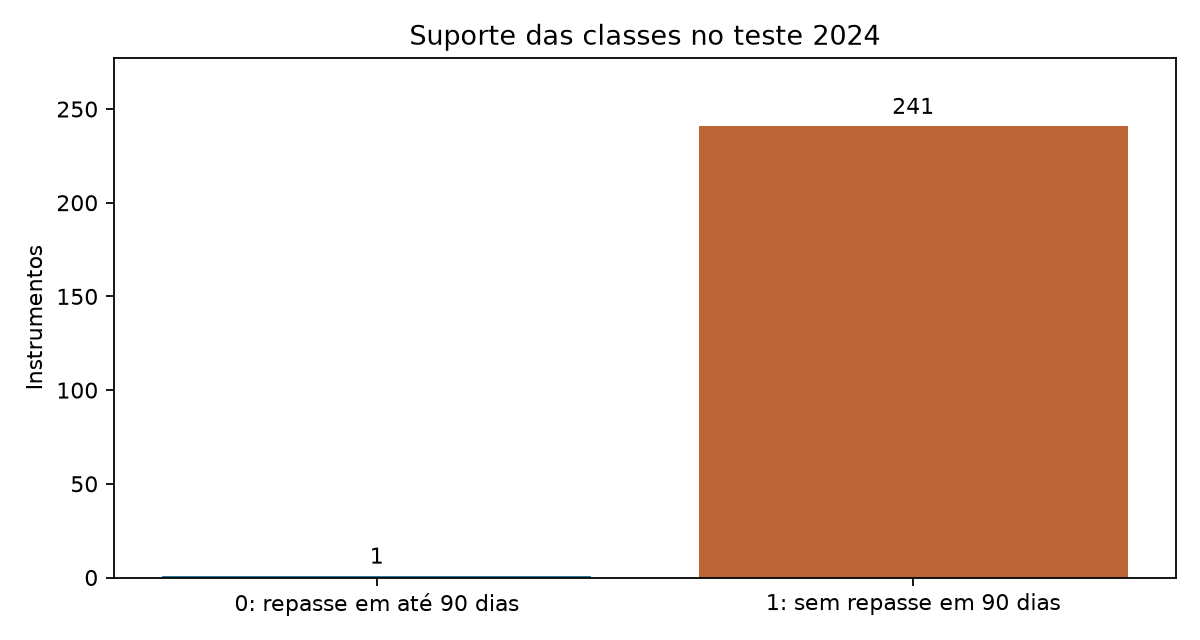

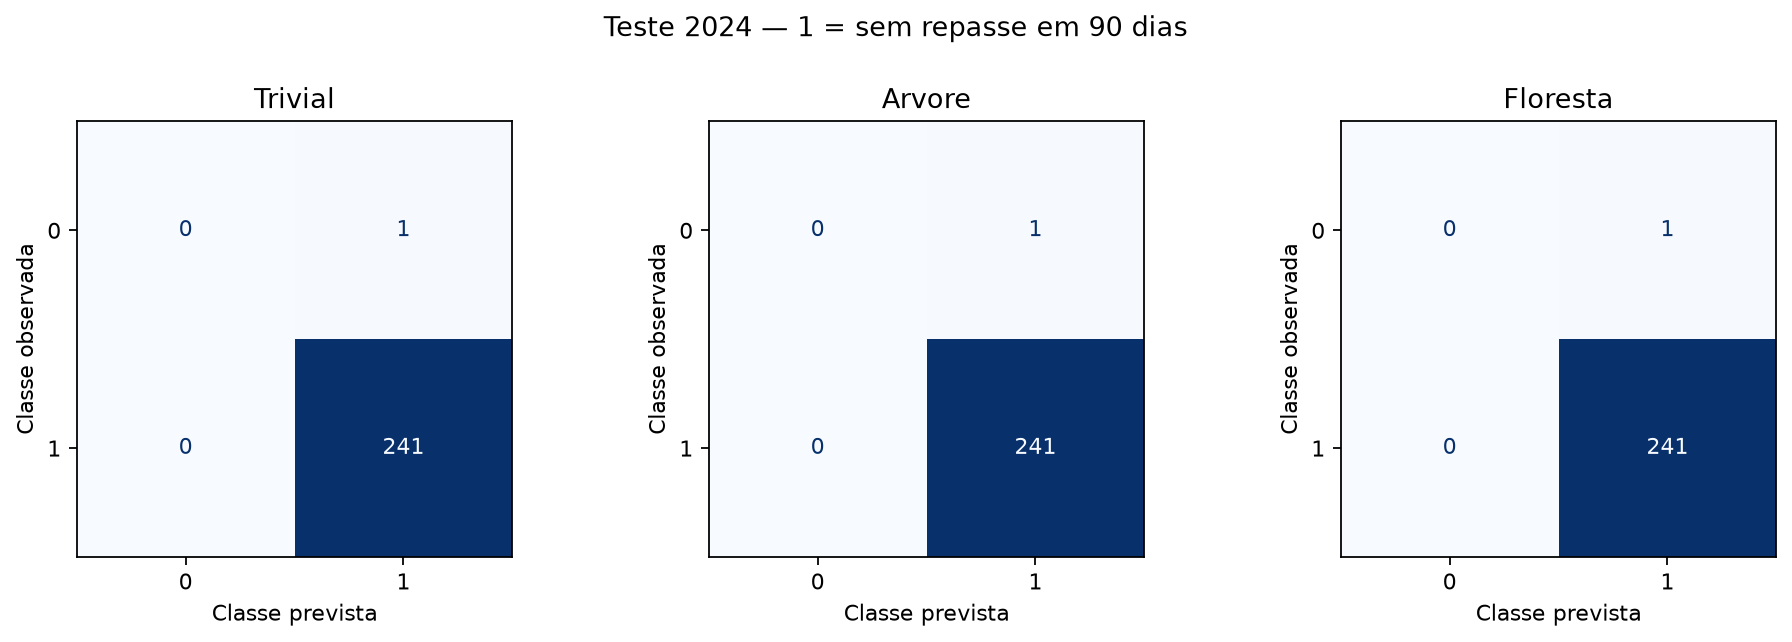

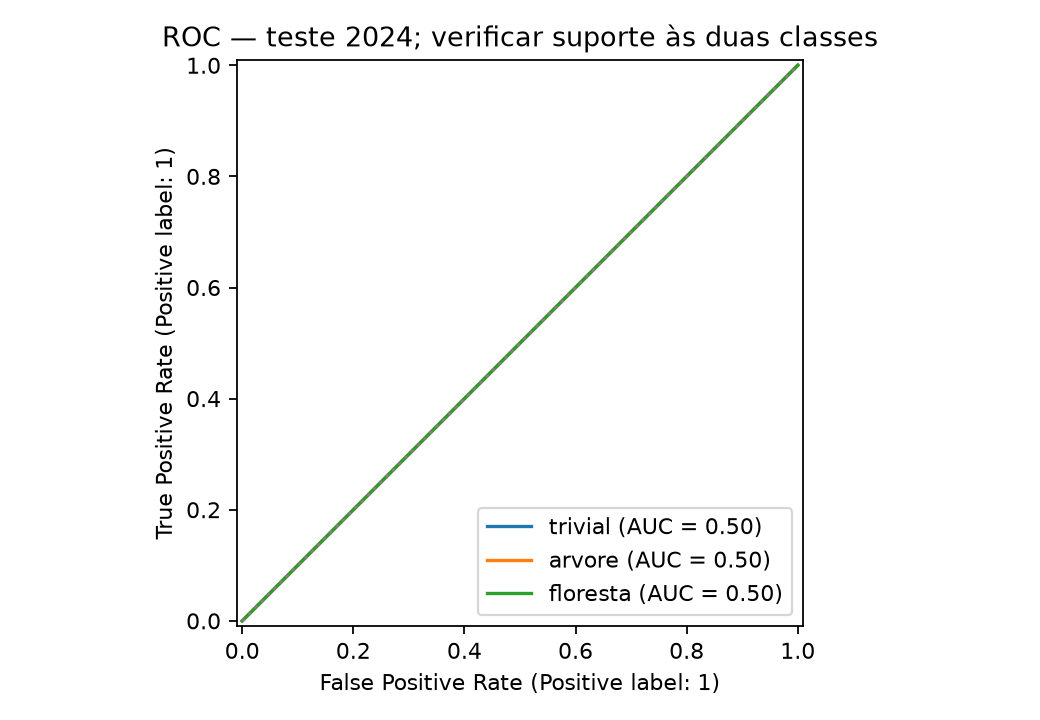

In [5]:
teste_metricas = tabela_metricas[tabela_metricas.particao == 'teste_2024']
display(teste_metricas[['nome', 'n', 'classe_0', 'classe_1', 'acuracia', 'acuracia_balanceada',
                       'roc_auc', 'average_precision', 'brier', 'status_ajuste']])
ids_por_modelo = predicoes.groupby('modelo').nr_convenio.apply(set)
assert all(ids == ids_por_modelo.iloc[0] for ids in ids_por_modelo)
# Comparação de reprodução com a execução de referência, se já existir.
referencia = PASTA / 'experimento/metricas.csv'
if referencia.exists():
    pd.testing.assert_frame_equal(tabela_metricas.reset_index(drop=True), pd.read_csv(referencia),
                                  check_dtype=False, check_exact=False, rtol=1e-12)
figuras(predicoes, PASTA / 'figuras_notebook')
display(Image(filename=str(PASTA / 'figuras_notebook/suporte_teste.png')))
display(Image(filename=str(PASTA / 'figuras_notebook/matrizes_confusao.png')))
display(Image(filename=str(PASTA / 'figuras_notebook/roc_teste.png')))

## 6. Diagnóstico de erros e confiabilidade

Inspecionar falsos positivos e negativos, não apenas a média. Um falso positivo aqui sinaliza ausência de repasse quando houve; não é um estouro de custo. Verificar também resultados por modalidade e município, reconhecendo o suporte reduzido.

O Brier pode parecer baixo quando a classe dominante quase sempre ocorre, mesmo sem discriminação. Probabilidade constante extrema não demonstra calibração operacional. Intervalos por bootstrap não são publicados com menos de dez casos da classe minoritária: um intervalo estreito para uma regra constante não resolveria a falta de informação.

In [6]:
erros = predicoes[(predicoes.modelo == 'arvore') & (predicoes.y_real != predicoes.y_previsto)]
detalhes = erros.merge(base[['nr_convenio', 'modalidade', 'orgao_superior', 'primeiro_repasse']],
                       on='nr_convenio', validate='one_to_one')
display(detalhes)
display(predicoes.groupby('modelo').agg(instrumentos=('nr_convenio', 'size'),
                                        probabilidades_distintas=('probabilidade', 'nunique')))
print('Incerteza:', resultados['intervalos'])
print('Conclusão:', resultados['status_conclusao'])

,nr_convenio,codigo_ibge,data_assinatura,y_real,modelo,probabilidade,y_previsto,modalidade,orgao_superior,primeiro_repasse
0,958535,2504009,2024-06-05,0,arvore,1.0,1,CONVENIO,MINISTERIO DO TURISMO,2024-07-05


,instrumentos,probabilidades_distintas
modelo,,
arvore,242,1
floresta,242,1
trivial,242,1


Incerteza: {'status': 'nao_estimado_suporte_minoritario_inferior_a_10', 'motivo': 'Evita intervalos aparentemente precisos com pouquíssimos exemplos de uma classe.'}
Conclusão: inviavel_discriminacao_treino_classe_unica


## 7. Conclusão, limites e defesa individual

Este estudo preserva o alvo solicitado e mostra sua limitação nesta população e nestes anos. No treino há somente instrumentos sem repasse em 90 dias; as árvores ajustadas viram respostas constantes e não superam a regra trivial em discriminação. A Logística não pode ser estimada. Isso é um diagnóstico estatístico do desenho do problema, não evidência de que Random Forest é sempre inadequado.

O uso de IBGE, receitas, pessoal e histórico de transferências foi implementado com datas anteriores, mas não cria exemplos de projetos pagos dentro da janela. Não há classificador operacional validado, não há previsão direta de estouro financeiro e não há estimativa definitiva de risco municipal.

O teste cobre um ano e poucos exemplos da classe minoritária. Revisões de dados e defasagem do registro no portal permanecem limitações. Qualquer revisão de horizonte, população ou momento da previsão deve ser versionada, acordada com a equipe e avaliada como outro experimento; não ajustar o alvo para melhorar o placar de 2024.

**Para explicar na avaliação:** por que purgar rótulos ainda desconhecidos; por que usar a mesma partição dos baselines; por que árvore de classe única não aprende separação; por que ROC-AUC constante vale 0,5; por que a Logística fica sem métrica; por que acurácia alta não implica utilidade.

**Uso de IA:** Codex auxiliou a implementação, a auditoria, os testes e a redação. Os resultados são calculados neste notebook, com dados públicos e código inspecionável. A equipe deve revisar e ser capaz de explicar cada bloco.